# How does a naive gradient step become Adam?

**Question:** What changes when a stateless gradient update gains a first moment, a second
moment, and a step counter?

An optimizer turns a gradient into a parameter change. The simplest rule uses today's gradient
directly and remembers nothing. We will add one piece of memory at a time until the resulting
rule is Adam. Only then will we compare it with `torch.optim.Adam`.

The two-element parameter and gradient are deliberately fixed. Every visual difference below
therefore comes from the update rule, not from a changing model or batch.

In [1]:
import altair as alt
import torch
from IPython.display import SVG, display
from torch import nn

from ml_sandbox.plotting import chart_to_svg

torch.manual_seed(7)

## 1. Start with no optimizer state

Naive gradient descent subtracts the current gradient scaled by learning rate $\alpha$:

$$\theta_t = \theta_{t-1} - \alpha g_t.$$

It cannot distinguish persistent direction from one noisy gradient, and it has no notion of a
coordinate's usual gradient scale.

In [2]:
initial_theta = torch.tensor([2.0, -1.0])
gradient = torch.tensor([0.5, 4.0])
learning_rate = 0.1

sgd_update = learning_rate * gradient
theta_after_sgd = initial_theta - sgd_update

torch.testing.assert_close(theta_after_sgd, torch.tensor([1.95, -1.4]))

The second coordinate changes eight times farther because its gradient is eight times larger.
There is no stored tensor beyond the parameter itself.

## 2. Add a first moment: remember recent direction

An exponential moving average combines the previous first moment with the current gradient:

$$m_t = \beta_1m_{t-1} + (1-\beta_1)g_t.$$

The next update can now depend on earlier gradients.

In [3]:
beta_1 = 0.9
first_moment = (1 - beta_1) * gradient
first_moment_update = learning_rate * first_moment

torch.testing.assert_close(first_moment, torch.tensor([0.05, 0.4]))

With $\beta_1=0.9$, the first observation receives 10% weight. Starting `m` at zero pulls the
early estimate toward zero, so we will correct that startup bias after adding scale memory.

## 3. Add a second moment: remember recent squared scale

A second moving average tracks squared gradients coordinate by coordinate:

$$v_t = \beta_2v_{t-1} + (1-\beta_2)g_t^2.$$

Dividing `m` by $\sqrt{v}$ expresses direction relative to each coordinate's recent scale.

In [4]:
beta_2 = 0.999
epsilon = 1e-8
second_moment = (1 - beta_2) * gradient.square()
raw_scaled_direction = first_moment / (second_moment.sqrt() + epsilon)
raw_scaled_update = learning_rate * raw_scaled_direction

torch.testing.assert_close(
    raw_scaled_direction, torch.full_like(gradient, 3.1623), rtol=0, atol=1e-4
)

Both averages began at zero, so their raw values are biased low. The first-step scaled direction
is about `3.1623` in both coordinates: scale normalization is present, but zero initialization
still distorts its magnitude.

## 4. Add the step counter: correct startup bias

The integer step tells us how much zero initialization remains in each moving average:

$$\hat{m}_t = \frac{m_t}{1-\beta_1^t}, \qquad
\hat{v}_t = \frac{v_t}{1-\beta_2^t}.$$

The complete update is

$$\Delta\theta_t = \alpha
\frac{\hat{m}_t}{\sqrt{\hat{v}_t}+\epsilon}.$$

[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-1

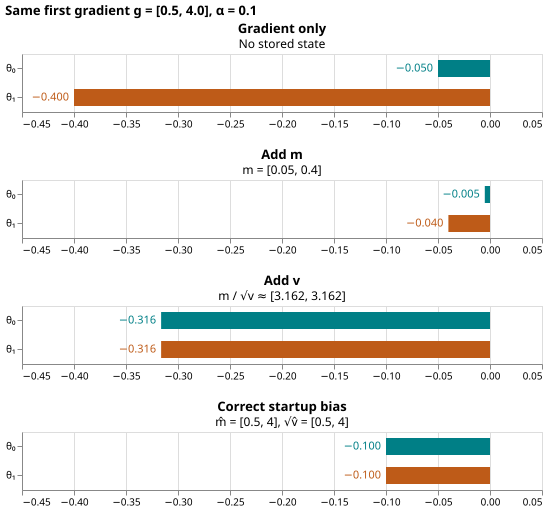

In [5]:
step = 1
corrected_first_moment = first_moment / (1 - beta_1**step)
corrected_second_moment = second_moment / (1 - beta_2**step)
adam_update = learning_rate * corrected_first_moment / (corrected_second_moment.sqrt() + epsilon)

torch.testing.assert_close(corrected_first_moment, gradient)
torch.testing.assert_close(corrected_second_moment, gradient.square())
torch.testing.assert_close(adam_update, torch.tensor([0.1, 0.1]))

# The four panels are intermediate calculations on the same first gradient.
first_step_stages = [
    ("Gradient only", "No stored state", -sgd_update),
    ("Add m", "m = [0.05, 0.4]", -first_moment_update),
    ("Add v", "m / √v ≈ [3.162, 3.162]", -raw_scaled_update),
    ("Correct startup bias", "m̂ = [0.5, 4], √v̂ = [0.5, 4]", -adam_update),
]
coordinate_names = ["θ₀", "θ₁"]
coordinate_colors = {"θ₀": "#007f86", "θ₁": "#be5b18"}
stage_charts = []

for stage_name, state_label, signed_changes in first_step_stages:
    stage_values = [
        {"coordinate": coordinate, "change": float(change), "zero": 0.0}
        for coordinate, change in zip(coordinate_names, signed_changes, strict=True)
    ]
    stage_base = alt.Chart(alt.Data(values=stage_values)).encode(
        y=alt.Y("coordinate:N", sort=coordinate_names, title=None),
        color=alt.Color(
            "coordinate:N",
            scale=alt.Scale(domain=coordinate_names, range=list(coordinate_colors.values())),
            legend=None,
        ),
    )
    stage_bar = stage_base.mark_bar(size=17).encode(
        x=alt.X("change:Q", scale=alt.Scale(domain=[-0.43, 0.02]), title=None),
        x2="zero:Q",
    )
    stage_value = stage_base.mark_text(align="right", dx=-5, color="#222222").encode(
        x="change:Q", text=alt.Text("change:Q", format=".3f")
    )
    stage_charts.append(
        alt.layer(stage_bar, stage_value).properties(
            title=alt.TitleParams(text=stage_name, subtitle=state_label), width=520, height=58
        )
    )

first_step_story = (
    alt.vconcat(*stage_charts, spacing=18)
    .resolve_scale(x="shared")
    .properties(title="Same first gradient g = [0.5, 4.0], α = 0.1")
)
display(SVG(chart_to_svg(first_step_story)))

The horizontal scale is shared across all four stages, and every bar is the signed change to
`theta` from the same first gradient. Adding `m` initially shrinks the change. Dividing by the
uncorrected `v` makes both changes about `−0.316`, revealing the zero-start distortion. Correcting
both moments yields the complete Adam change of `−0.1` in each coordinate. The two state vectors
always match `theta` in shape.

## 5. Carry the state across several gradients

The full update remains visible in the loop. `m`, `v`, and `step` persist after each iteration;
the gradient is merely the new input.

In [6]:
gradient_sequence = torch.tensor([[0.5, 4.0], [0.25, -2.0], [-0.75, 1.0], [0.1, -0.5]])
manual_theta = nn.Parameter(initial_theta.clone())
first_moment = torch.zeros_like(manual_theta)
second_moment = torch.zeros_like(manual_theta)
step = 0

manual_trajectory = [manual_theta.detach().clone()]
corrected_first_history = []
rms_scale_history = []
signed_change_history = []

for current_gradient in gradient_sequence:
    step += 1
    first_moment = beta_1 * first_moment + (1 - beta_1) * current_gradient
    second_moment = beta_2 * second_moment + (1 - beta_2) * current_gradient.square()
    corrected_first_moment = first_moment / (1 - beta_1**step)
    corrected_second_moment = second_moment / (1 - beta_2**step)
    update = learning_rate * corrected_first_moment / (corrected_second_moment.sqrt() + epsilon)

    with torch.no_grad():
        manual_theta -= update

    manual_trajectory.append(manual_theta.detach().clone())
    corrected_first_history.append(corrected_first_moment.clone())
    rms_scale_history.append(corrected_second_moment.sqrt())
    signed_change_history.append(-update.clone())

assert first_moment.shape == manual_theta.shape
assert second_moment.shape == manual_theta.shape
assert step == len(gradient_sequence)

[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.


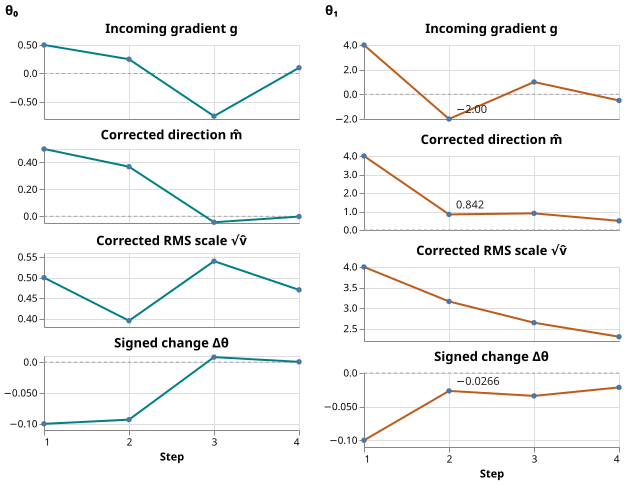

In [7]:
theta_history = torch.stack(manual_trajectory)
corrected_first_values = torch.stack(corrected_first_history)
rms_scale_values = torch.stack(rms_scale_history)
signed_change_values = torch.stack(signed_change_history)

state_metrics = [
    ("Incoming gradient g", gradient_sequence),
    ("Corrected direction m̂", corrected_first_values),
    ("Corrected RMS scale √v̂", rms_scale_values),
    ("Signed change Δθ", signed_change_values),
]
coordinate_stories = []

for coordinate_index, coordinate_name in enumerate(coordinate_names):
    metric_charts = []
    for metric_index, (metric_name, history) in enumerate(state_metrics):
        observations = [
            {"step": time, "value": float(value)}
            for time, value in enumerate(history[:, coordinate_index], start=1)
        ]
        base = alt.Chart(alt.Data(values=observations)).encode(
            x=alt.X(
                "step:Q",
                scale=alt.Scale(domain=[1, 4], nice=False),
                axis=alt.Axis(
                    values=[1, 2, 3, 4],
                    labels=metric_index == 3,
                    ticks=metric_index == 3,
                    title="Step" if metric_index == 3 else None,
                ),
            ),
            y=alt.Y(
                "value:Q",
                title=None,
                scale=alt.Scale(zero=metric_index != 2),
                axis=alt.Axis(tickCount=3, format=".2g"),
            ),
        )
        line = base.mark_line(point=True, color=coordinate_colors[coordinate_name])
        plot = line
        if metric_index != 2:
            zero_line = (
                alt.Chart(alt.Data(values=[{"zero": 0}]))
                .mark_rule(color="#a6a6a6", strokeDash=[3, 3])
                .encode(y="zero:Q")
            )
            plot = alt.layer(zero_line, line)
        if coordinate_index == 1 and metric_index in (0, 1, 3):
            step_two = (
                base.transform_filter(alt.datum.step == 2)
                .mark_text(align="left", dx=7, dy=-9, color="#222222")
                .encode(text=alt.Text("value:Q", format=".3g"))
            )
            plot = alt.layer(plot, step_two)
        metric_charts.append(plot.properties(title=metric_name, width=255, height=74))
    coordinate_stories.append(
        alt.vconcat(*metric_charts, spacing=8).properties(title=coordinate_name)
    )

memory_story = alt.hconcat(*coordinate_stories, spacing=22)
display(SVG(chart_to_svg(memory_story)))

Read each column from top to bottom: the incoming gradient updates a signed direction and a
non-negative RMS scale, which together determine the signed change to that coordinate. At step 2,
`g[1]` flips to `−2`, yet `m̂[1]` remains about `+0.842`; `theta[1]` still moves by about `−0.0266`.
Each strip has its own labeled scale so small changes remain visible. The plotted state vectors
have shape `(2,)`, matching `theta`, while the scalar `step` supplies their age.

## 6. Verify the result against PyTorch

PyTorch now receives the same initial parameter and gradient sequence. The assertions compare
every parameter step plus the final `m`, `v`, and step. The visual story concerns the optimizer
mechanism; these checks establish numerical parity.

In [8]:
reference_theta = nn.Parameter(initial_theta.clone())
reference_optimizer = torch.optim.Adam(
    [reference_theta],
    lr=learning_rate,
    betas=(beta_1, beta_2),
    eps=epsilon,
)
reference_trajectory = [reference_theta.detach().clone()]

for current_gradient in gradient_sequence:
    reference_theta.grad = current_gradient.clone()
    reference_optimizer.step()
    reference_optimizer.zero_grad(set_to_none=True)
    reference_trajectory.append(reference_theta.detach().clone())

for manual_value, reference_value in zip(manual_trajectory, reference_trajectory, strict=True):
    torch.testing.assert_close(manual_value, reference_value, rtol=1e-6, atol=1e-7)

reference_state = reference_optimizer.state[reference_theta]
torch.testing.assert_close(first_moment, reference_state["exp_avg"])
torch.testing.assert_close(second_moment, reference_state["exp_avg_sq"])
assert step == int(reference_state["step"].item())

The manual parameter trajectory and final optimizer state agree with PyTorch within the asserted
floating-point tolerance.

## 7. Experiment: keep the parameter, reset the optimizer

Both branches start from the same mature parameter and receive the same next gradient. One
keeps `m`, `v`, and `step`; the other starts them at zero. The shared horizontal scale below shows
how much the very next parameter change depends on that choice.

[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.
[2026-10-10T19:57:21Z WARN  vl_convert_rs::text] Fallback from Arial to Arial Unicode MS.


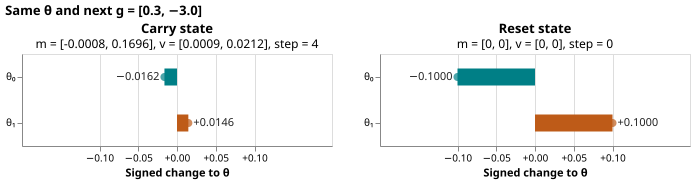

In [9]:
next_gradient = torch.tensor([0.3, -3.0])

continued_step = step + 1
continued_first_moment = beta_1 * first_moment + (1 - beta_1) * next_gradient
continued_second_moment = beta_2 * second_moment + (1 - beta_2) * next_gradient.square()
continued_first_corrected = continued_first_moment / (1 - beta_1**continued_step)
continued_second_corrected = continued_second_moment / (1 - beta_2**continued_step)
continued_update = (
    learning_rate * continued_first_corrected / (continued_second_corrected.sqrt() + epsilon)
)

fresh_step = 1
fresh_first_moment = (1 - beta_1) * next_gradient
fresh_second_moment = (1 - beta_2) * next_gradient.square()
fresh_first_corrected = fresh_first_moment / (1 - beta_1**fresh_step)
fresh_second_corrected = fresh_second_moment / (1 - beta_2**fresh_step)
fresh_update = learning_rate * fresh_first_corrected / (fresh_second_corrected.sqrt() + epsilon)

assert not torch.allclose(continued_update, fresh_update)

branch_states = [
    (
        "Carry state",
        (
            f"m = {[round(float(value), 4) for value in first_moment]}, "
            f"v = {[round(float(value), 4) for value in second_moment]}, step = {step}"
        ),
        -continued_update,
    ),
    ("Reset state", "m = [0, 0], v = [0, 0], step = 0", -fresh_update),
]
branch_charts = []

for branch_name, state_label, signed_changes in branch_states:
    branch_values = [
        {"coordinate": coordinate, "change": float(change), "zero": 0.0}
        for coordinate, change in zip(coordinate_names, signed_changes, strict=True)
    ]
    base = alt.Chart(alt.Data(values=branch_values)).encode(
        y=alt.Y("coordinate:N", sort=coordinate_names, title=None),
        color=alt.Color(
            "coordinate:N",
            scale=alt.Scale(domain=coordinate_names, range=list(coordinate_colors.values())),
            legend=None,
        ),
    )
    arrow = base.mark_bar(size=17).encode(
        x=alt.X(
            "change:Q",
            scale=alt.Scale(domain=[-0.155, 0.155]),
            title="Signed change to θ",
            axis=alt.Axis(values=[-0.1, -0.05, 0, 0.05, 0.1], format="+.2f"),
        ),
        x2="zero:Q",
    )
    endpoint = base.mark_point(filled=True, size=65).encode(x="change:Q")
    label_base = alt.Chart(alt.Data(values=branch_values)).encode(
        x="change:Q",
        y=alt.Y("coordinate:N", sort=coordinate_names, title=None),
        text=alt.Text("change:Q", format="+.4f"),
    )
    negative_label = label_base.transform_filter(alt.datum.change < 0).mark_text(
        align="right", dx=-5, color="#222222"
    )
    positive_label = label_base.transform_filter(alt.datum.change > 0).mark_text(
        align="left", dx=5, color="#222222"
    )
    branch_charts.append(
        alt.layer(arrow, endpoint, negative_label, positive_label).properties(
            title=alt.TitleParams(text=branch_name, subtitle=state_label), width=310, height=92
        )
    )

fork_story = alt.hconcat(*branch_charts, spacing=30).properties(
    title="Same θ and next g = [0.3, −3.0]"
)
display(SVG(chart_to_svg(fork_story)))

Both lanes start from the same `theta` and use the same gradient. Carrying state produces signed
changes of about `[−0.0162, +0.0146]`; resetting state produces `[−0.1, +0.1]`. The fresh branch
moves farther because its first observation gives an approximately sign-sized Adam step. The
carried branch interprets that observation through previous direction, scale, and age.

## What Adam remembers

The naive update measures only today's gradient. Adding `m` remembers recent direction; adding
`v` remembers recent squared scale; adding `step` makes their startup correction well-defined.
Adam's update is the current gradient interpreted through those three persistent state values.
Keeping the parameter but resetting that state therefore starts a different optimization
trajectory.